In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
# Load CSV
players = pd.read_csv("../basketballPlayoffs/players_teams.csv")

In [23]:
# Total number of unique teams
num_teams = players['tmID'].nunique()
print(f"Total number of unique teams: {num_teams}")

# Frequency of each team
team_counts = players['tmID'].value_counts()
print("\nFrequency of each team:")
print(team_counts)



Total number of unique teams: 20

Frequency of each team:
tmID
PHO    152
DET    147
SEA    136
WAS    135
LAS    132
IND    131
NYL    130
MIN    126
SAC    122
HOU    118
CHA     91
CON     88
SAS     79
CHI     54
CLE     52
MIA     40
ORL     39
UTA     39
POR     38
ATL     27
Name: count, dtype: int64


In [24]:
# Total number of unique stints
num_stints = players['stint'].nunique()
print(f"Total number of unique stints: {num_stints}")


Total number of unique stints: 4


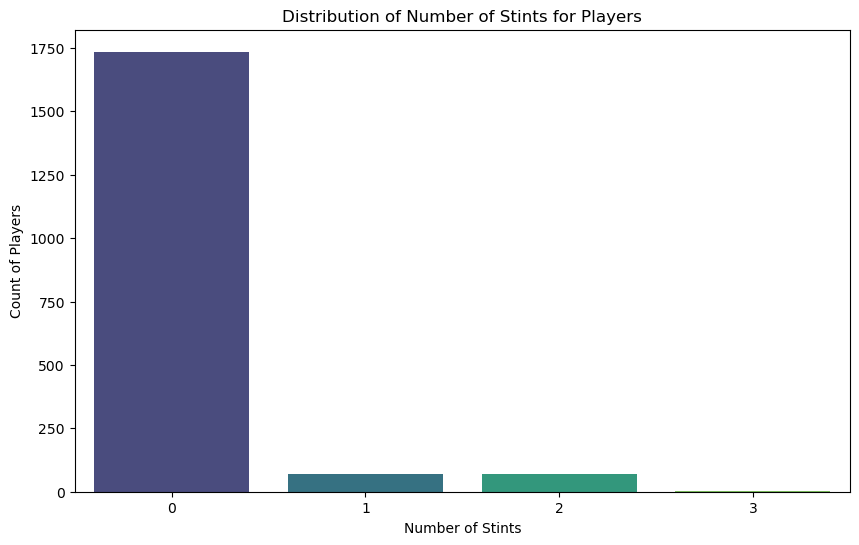

In [30]:
# Count the frequency of each unique stint value
stint_counts = players['stint'].value_counts().sort_index()

# Plot the distribution of stint counts
plt.figure(figsize=(10, 6))
sns.barplot(x=stint_counts.index, y=stint_counts.values, palette='viridis')

# Add titles and labels
plt.title('Distribution of Number of Stints for Players')
plt.xlabel('Number of Stints')
plt.ylabel('Count of Players')
plt.xticks(rotation=0)
plt.show()

In [25]:
# Check for null values in each column
null_counts = players.isnull().sum()
print("Null values in each column:")
print(null_counts)

# Alternatively, display only columns that contain null values
null_columns = null_counts[null_counts > 0]
print("\nColumns with null values:")
print(null_columns)


Null values in each column:
playerID              0
year                  0
stint                 0
tmID                  0
lgID                  0
GP                    0
GS                    0
minutes               0
points                0
oRebounds             0
dRebounds             0
rebounds              0
assists               0
steals                0
blocks                0
turnovers             0
PF                    0
fgAttempted           0
fgMade                0
ftAttempted           0
ftMade                0
threeAttempted        0
threeMade             0
dq                    0
PostGP                0
PostGS                0
PostMinutes           0
PostPoints            0
PostoRebounds         0
PostdRebounds         0
PostRebounds          0
PostAssists           0
PostSteals            0
PostBlocks            0
PostTurnovers         0
PostPF                0
PostfgAttempted       0
PostfgMade            0
PostftAttempted       0
PostftMade            0
PostthreeAtt

In [33]:
# List of columns to check
columns_to_check = ["GP","GS","minutes","points","oRebounds","dRebounds","rebounds",
                    "assists","steals","blocks","turnovers","PF","fgAttempted","fgMade",
                    "ftAttempted","ftMade","threeAttempted","threeMade","dq",
                    "PostGP","PostGS","PostMinutes","PostPoints","PostoRebounds",
                    "PostdRebounds","PostRebounds","PostAssists","PostSteals",
                    "PostBlocks","PostTurnovers","PostPF","PostfgAttempted",
                    "PostfgMade","PostftAttempted","PostftMade","PostthreeAttempted",
                    "PostthreeMade","PostDQ"]

# Dictionary to store players with max values for each statistic
max_players = {}

# Find the player with the maximum value for each column along with their ID, year, and max value
for column in columns_to_check:
    max_player_row = players.loc[players[column].idxmax()]  # Get the row with the max value
    player_id = max_player_row["playerID"]                   # Get player ID
    year = max_player_row["year"]                            # Get year of the max value
    max_value = max_player_row[column]                       # Get max value for the statistic
    max_players[column] = (player_id, year, max_value)       # Store player ID, year, and value

# Display the results
for stat, (player, year, value) in max_players.items():
    print(f"Player with max {stat}: {player}, Year: {year}, Value: {value}")


Player with max GP: abrossv01w, Year: 7, Value: 34
Player with max GS: anosini01w, Year: 9, Value: 34
Player with max minutes: smithka01w, Year: 2, Value: 1234
Player with max points: tauradi01w, Year: 7, Value: 860
Player with max oRebounds: griffyo01w, Year: 2, Value: 162
Player with max dRebounds: leslili01w, Year: 5, Value: 276
Player with max rebounds: fordch01w, Year: 7, Value: 363
Player with max assists: penicti01w, Year: 1, Value: 236
Player with max steals: catchta01w, Year: 10, Value: 99
Player with max blocks: dydekma01w, Year: 2, Value: 113
Player with max turnovers: leslili01w, Year: 7, Value: 126
Player with max PF: fordch01w, Year: 6, Value: 143
Player with max fgAttempted: tauradi01w, Year: 7, Value: 660
Player with max fgMade: tauradi01w, Year: 7, Value: 298
Player with max ftAttempted: smithka01w, Year: 2, Value: 275
Player with max ftMade: smithka01w, Year: 2, Value: 246
Player with max threeAttempted: tauradi01w, Year: 7, Value: 305
Player with max threeMade: taura

In [34]:
# List of columns to sum for each player
columns_to_sum = ["GP","GS","minutes","points","oRebounds","dRebounds","rebounds",
                  "assists","steals","blocks","turnovers","PF","fgAttempted","fgMade",
                  "ftAttempted","ftMade","threeAttempted","threeMade","dq",
                  "PostGP","PostGS","PostMinutes","PostPoints","PostoRebounds",
                  "PostdRebounds","PostRebounds","PostAssists","PostSteals",
                  "PostBlocks","PostTurnovers","PostPF","PostfgAttempted",
                  "PostfgMade","PostftAttempted","PostftMade","PostthreeAttempted",
                  "PostthreeMade","PostDQ"]

# Group by playerID and sum the statistics across years
player_summed_stats = players.groupby("playerID")[columns_to_sum].sum()

# Dictionary to store the player with the maximum value for each statistic
max_players = {}

# Find the player with the maximum summed value for each statistic
for column in columns_to_sum:
    max_player_id = player_summed_stats[column].idxmax()  # Get playerID with max value for the column
    max_value = player_summed_stats[column].max()         # Get max value for the column
    max_players[column] = (max_player_id, max_value)      # Store playerID and the summed max value

# Display the results
for stat, (player, value) in max_players.items():
    print(f"Player with max summed {stat}: {player}, Summed Value: {value}")


Player with max summed GP: melvich01w, Summed Value: 327
Player with max summed GS: johnsvi01w, Summed Value: 321
Player with max summed minutes: smithka01w, Summed Value: 11059
Player with max summed points: jacksla01w, Summed Value: 5101
Player with max summed oRebounds: griffyo01w, Summed Value: 908
Player with max summed dRebounds: leslili01w, Summed Value: 1838
Player with max summed rebounds: leslili01w, Summed Value: 2508
Player with max summed assists: penicti01w, Summed Value: 1728
Player with max summed steals: catchta01w, Summed Value: 631
Player with max summed blocks: dydekma01w, Summed Value: 686
Player with max summed turnovers: leslili01w, Summed Value: 888
Player with max summed PF: leslili01w, Summed Value: 1041
Player with max summed fgAttempted: thompti01w, Summed Value: 4017
Player with max summed fgMade: leslili01w, Summed Value: 1788
Player with max summed ftAttempted: leslili01w, Summed Value: 1603
Player with max summed ftMade: smithka01w, Summed Value: 1237
Pl

<Axes: title={'center': 'Regular Season vs Postseason Points by Team'}, xlabel='tmID'>

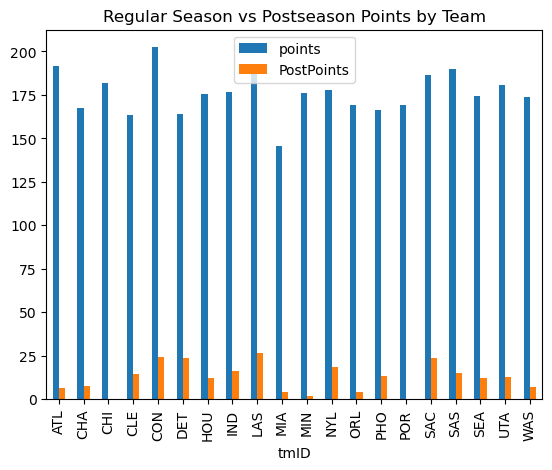

In [26]:
team_performance = players.groupby('tmID').agg({
    'points': 'mean',
    'PostPoints': 'mean'
}).reset_index()

team_performance.plot(x='tmID', y=['points', 'PostPoints'], kind='bar', title='Regular Season vs Postseason Points by Team')


In [27]:
top_performers = players.loc[players['points'].idxmax()]
print(f"Top performer in regular season: {top_performers['playerID']} with {top_performers['points']} points")


Top performer in regular season: tauradi01w with 860 points


In [28]:
top_performers = players.loc[players['PostPoints'].idxmax()]
print(f"Top performer in postseason: {top_performers['playerID']} with {top_performers['PostPoints']} points")


Top performer in postseason: tauradi01w with 245 points


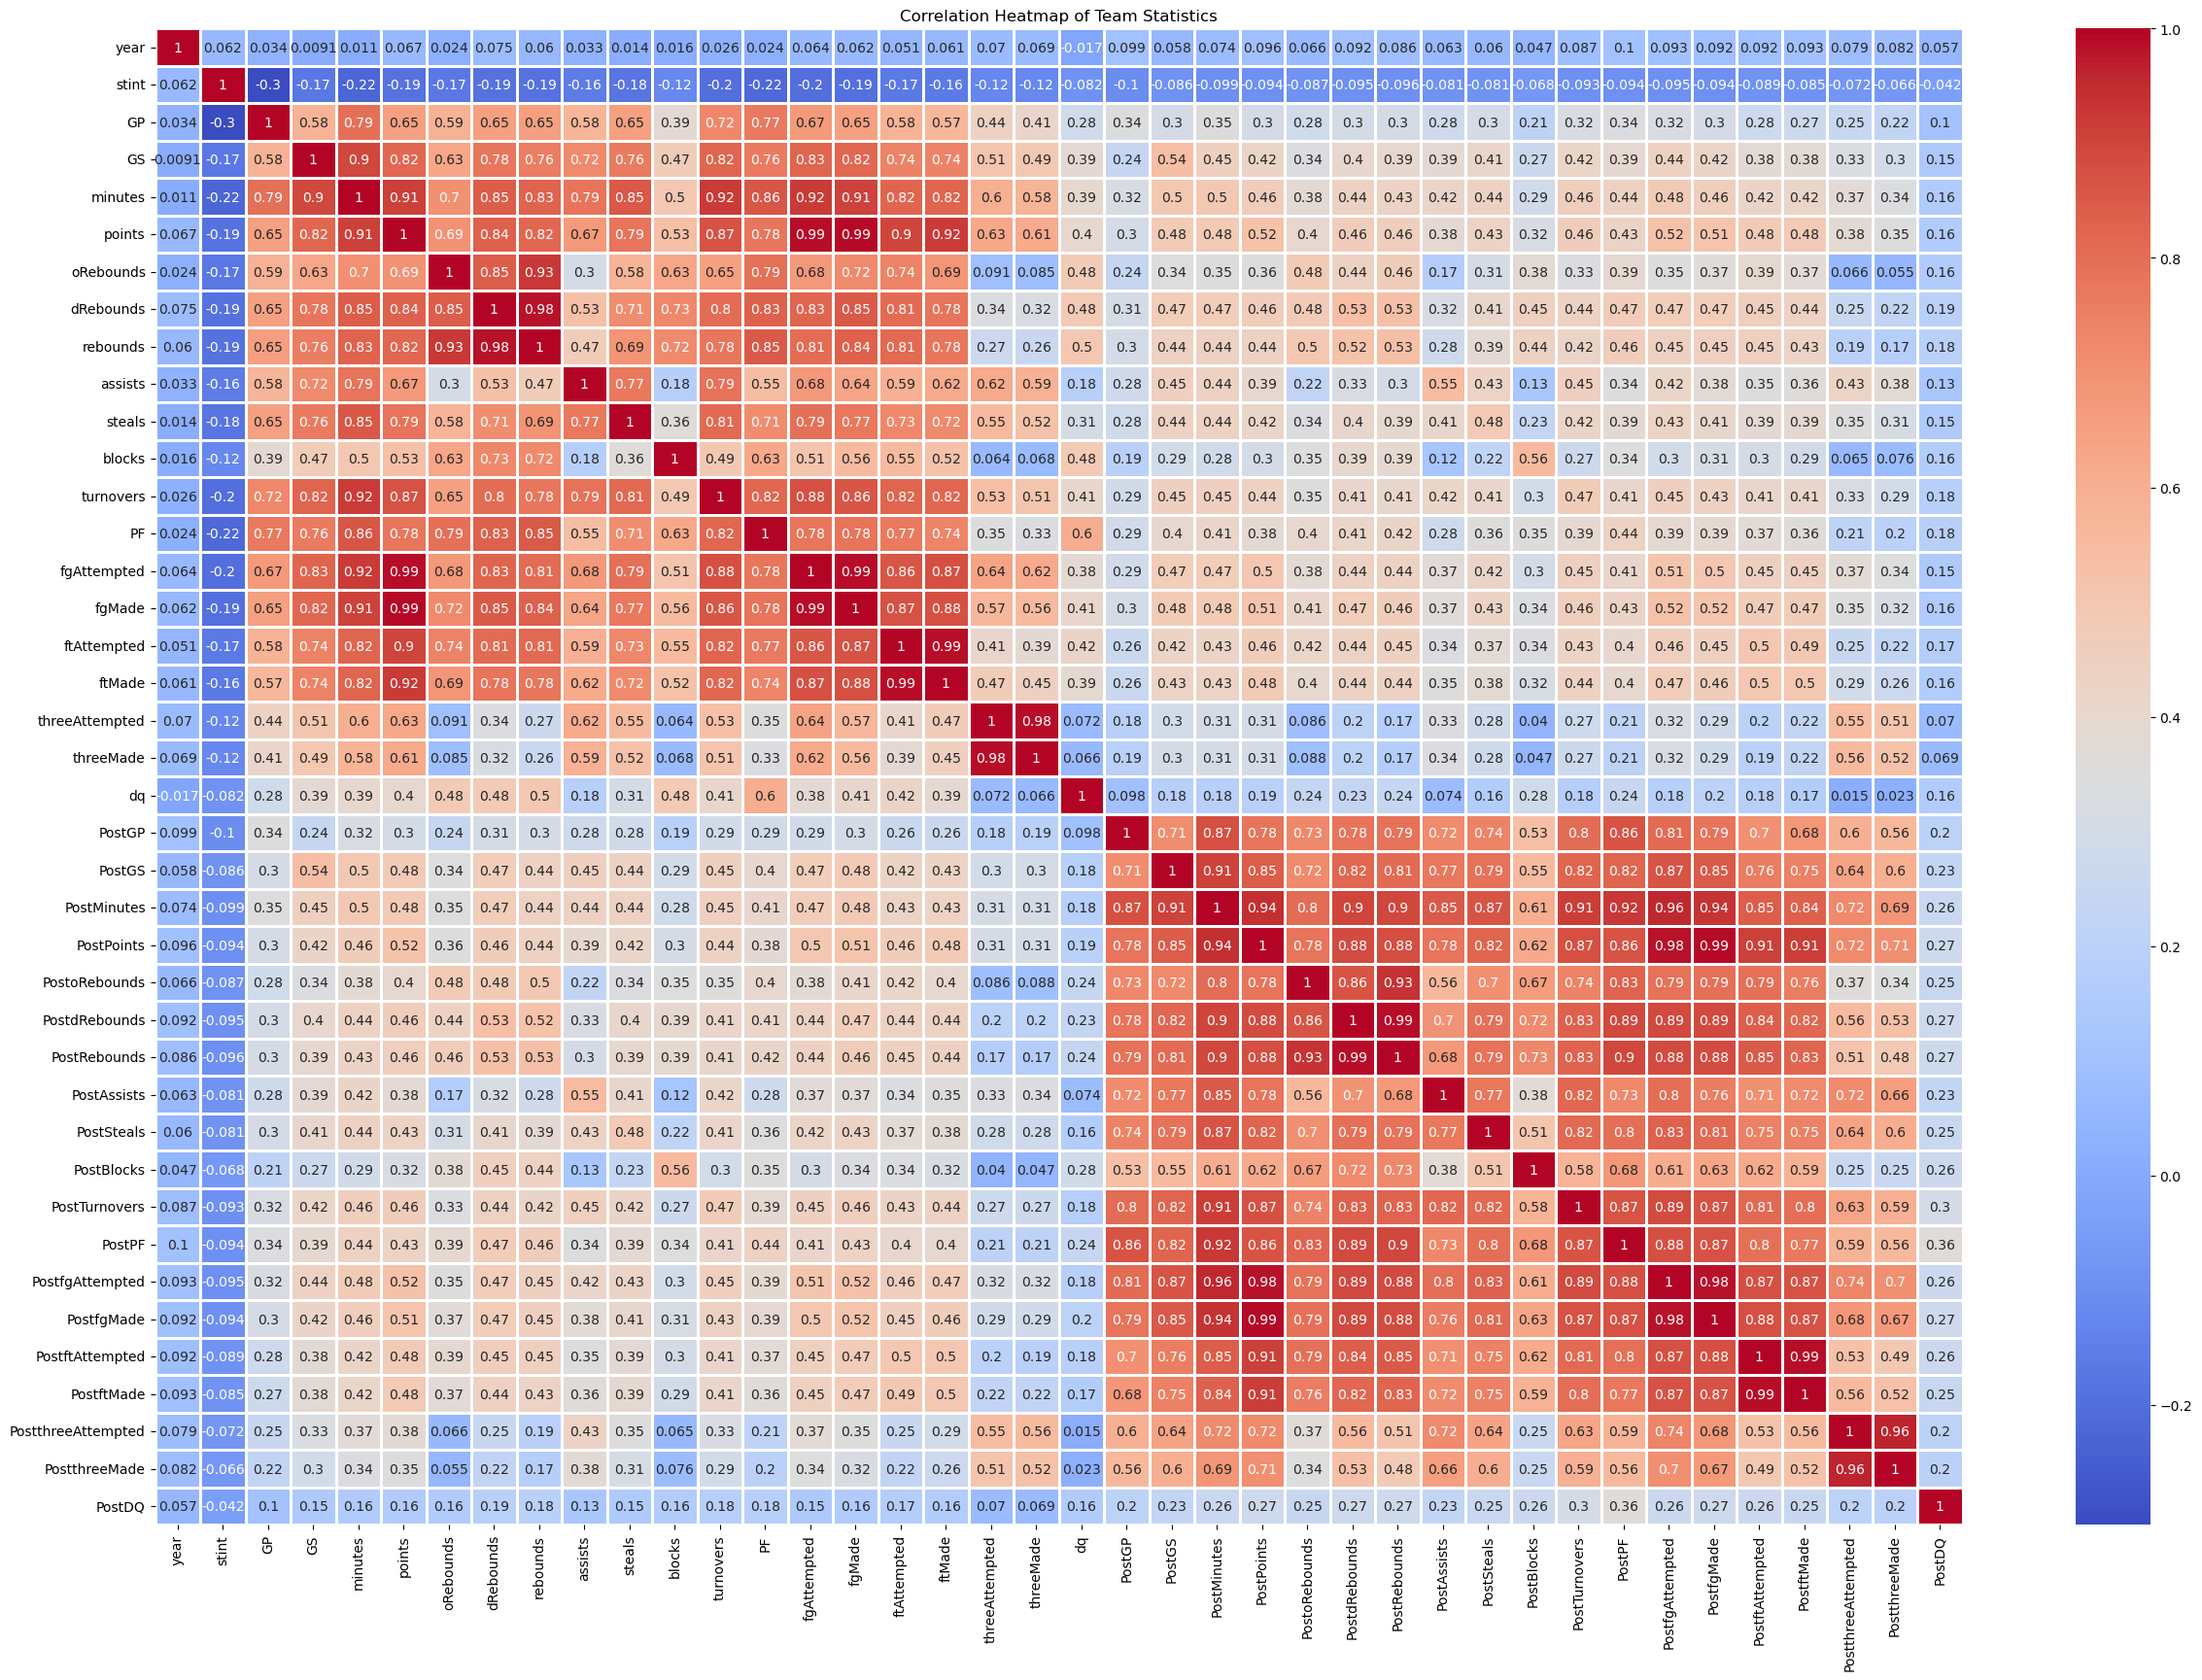

In [29]:
players = players.loc[:, (players != 0).any(axis=0)] # Eliminar Noisy Columns (que so têm 0)
data_numeric=players.select_dtypes(['number'])
correlation_matrix = data_numeric.corr()

plt.figure(figsize=(30, 20))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", linewidths=1)
plt.title("Correlation Heatmap of Team Statistics")
plt.show()